<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/fabiobento/lab-cont-2026-2-privado/blob/main/modulo2_plano_s/labs/gabarito_lab07_avanco_de_fase.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
</table>

# Gabarito — Lab 07: Controlador de Avanço de Fase

**Módulo 02 · Semana 7 · Laboratório de Controle Automático (Ifes Guarapari)**

> **Documento do professor.** Reproduz o `lab07_avanco_de_fase.ipynb` do aluno com comentários teóricos
> estendidos, as equações em LaTeX e — ao final — a resolução completa dos três itens de "Sua vez"
> (entregue no relatório).

Neste laboratório vamos:
1. Confirmar a **impossibilidade do controle P** para certos requisitos;
2. Implementar `projetar_avanco` com as três soluções-padrão (cancelamento, embaixo, bissetriz);
3. Ver por que o **PD puro não se implementa** (o pico do sinal de controle) e como o filtro resolve;
4. Refazer o **projeto em dois estágios** e testar a **regra dos 40°**.

**Teoria de apoio:** `teoria_modulo2.md`, §2.3 (avanço de fase). Exercícios de referência:
`exercicios_resolvidos_modulo2.md`, Exercícios 2.3.1–2.3.3.

In [1]:
# %% IMPORTS (rode esta célula primeiro)
import control as ct
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (9, 4)
plt.rcParams['axes.grid'] = True

def step(G, t):
    t, y = ct.step_response(G, t)
    return np.asarray(t), np.asarray(y)

def medir(T, t=None):
    if t is None: t = np.linspace(0, 30, 30000)
    t, y = step(T, t)
    yss = y[-1]
    Mp = 100*(y.max()-yss)/yss; tp = t[np.argmax(y)]
    tr = t[np.argmax(y >= yss)]
    fora = np.where(np.abs(y-yss) > 0.05*abs(yss))[0]
    ts = t[fora[-1]] if len(fora) else 0.0
    return dict(Mp=Mp, tp=tp, tr=tr, ts=ts, yss=yss)

def angulo_G(G, ponto):
    fase = 0.0
    for z in ct.zeros(G):
        fase += np.degrees(np.arctan2(ponto.imag - z.imag, ponto.real - z.real))
    for p in ct.poles(G):
        fase -= np.degrees(np.arctan2(ponto.imag - p.imag, ponto.real - p.real))
    return (fase + 180) % 360 - 180

def projetar_avanco(G, sd, A=1.0, modo='cancelamento', polo_cancela=None):
    """Projeta C(s) = k(s+a)/(s+b) para que sd seja polo de MF.
    modo: 'cancelamento' (zero sobre polo_cancela da planta),
          'embaixo' (zero sob sd), 'bissetriz' (mínimo ganho)."""
    phi = (-angulo_G(G, sd) - 180) % 360  # contribuição necessária (>0 = avanço)
    assert 0 < phi <= 40, f'avanço {phi:.1f}° fora do limite de 40°!'
    sig, wd = -sd.real, sd.imag
    if modo == 'cancelamento':
        a = polo_cancela
        fz = np.degrees(np.arctan2(wd, a - sig))
        fp = fz - phi
        b = sig + wd/np.tan(np.radians(fp))
    elif modo == 'embaixo':
        a = sig
        b = sig + wd/np.tan(np.radians(90 - phi))
    elif modo == 'bissetriz':
        a = sig - wd*np.tan(np.radians(phi/2))
        b = sig + wd*np.tan(np.radians(phi/2))
    C = ct.tf([1, a], [1, b])
    CG = C*G
    dpolos = np.prod([abs(sd - p) for p in ct.poles(CG)])
    dzeros = np.prod([abs(sd - z) for z in ct.zeros(CG)]) if len(ct.zeros(CG)) else 1.0
    k = dpolos/(A*dzeros)
    return k*C, phi

print('python-control', ct.__version__)

python-control 0.10.2


## Parte 1 — A impossibilidade do P

$G(s) = \dfrac{4}{s(s+4)}$: o LGR é a vertical em $-2$. Requisito $t_s(5\%) \leq 1$ s ($\sigma \geq 3$)?
**Impossível** — o LGR nunca passa à esquerda de $-2$ (§2.3.1). Veja:

/tmp/ipykernel_248/3172231251.py:2: FutureWarning: keyword 'kvect' is deprecated; use 'gains'
  ct.rlocus(G, kvect=np.linspace(0, 200, 2000))


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


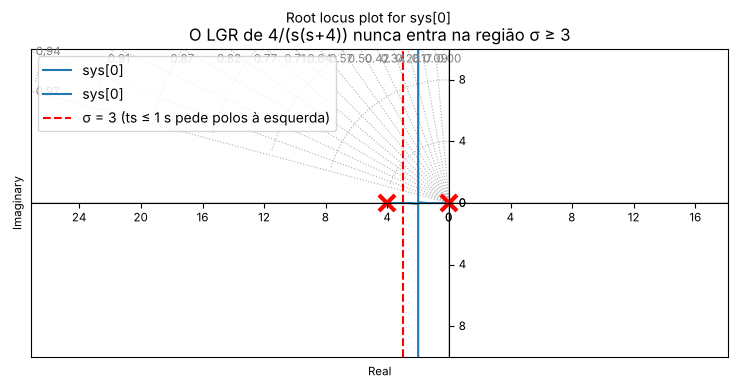

In [2]:
G = ct.tf([4], [1, 4, 0])
ct.rlocus(G, kvect=np.linspace(0, 200, 2000))
plt.axvline(-3, color='r', ls='--', label='σ = 3 (ts ≤ 1 s pede polos à esquerda)')
plt.plot([0, -4], [0, 0], 'rx', ms=12, mew=3)
plt.xlim(-10, 1); plt.ylim(-10, 10); plt.legend()
plt.title('O LGR de 4/(s(s+4)) nunca entra na região σ ≥ 3');

In [3]:
# Conferindo os dois "requisitos conflitantes" da teoria (§2.3.1): Mp ≤ 5% e tp ≤ 1 s
for nome, sd_ in [('Mp = 5%  (ζ=0,69 → β=46,4°)', -2 + 2.1j), ('tp = 1 s  (ωd = π)', -2 + np.pi*1j)]:
    k = abs(sd_)*abs(sd_ + 4)/4
    T = ct.feedback(k*G, 1)
    m = medir(T, np.linspace(0, 8, 8000))
    zeta = -sd_.real/abs(sd_)
    print(f'{nome:28s}: polos {sd_:.2f}  k = {k:.2f}  ζ = {zeta:.2f}  →  Mp = {m["Mp"]:.1f}%, tp = {m["tp"]:.2f} s')

Mp = 5%  (ζ=0,69 → β=46,4°) : polos -2.00+2.10j  k = 2.10  ζ = 0.69  →  Mp = 5.0%, tp = 1.50 s
tp = 1 s  (ωd = π)          : polos -2.00+3.14j  k = 3.47  ζ = 0.54  →  Mp = 13.5%, tp = 1.00 s


**Leitura do resultado.** Para $G(s)=\dfrac{4}{s(s+4)}$ o LGR é o trecho $(-4,0)$ mais a vertical em
$\sigma=-4/2=-2$: **nenhum** ramo entra em $\sigma\geq3$, então $t_s(5\%)=3/\sigma\geq1{,}5$ s para **qualquer** $k$.
E mesmo requisitos alcançáveis podem ser **conflitantes** entre si: subindo na vertical até $\zeta=0{,}69$
($-2\pm2{,}1j$, $k\approx2{,}1$) o overshoot fica em $\approx5\%$, mas $t_p\approx1{,}5$ s ✗; subindo até $\omega_d=\pi$
($-2\pm3{,}14j$, $k\approx3{,}47$) o $t_p$ cai a $1$ s, mas $\zeta=0{,}54$ e o overshoot vai a $\approx13\%$ ✗. **Moral:** o
P só escolhe pontos **sobre** o LGR; para colocar polos **fora** dele é preciso **mudar o LGR** — e quem faz
isso são os polos e zeros acrescentados pelo controlador.

## Parte 2 — Projetando o avanço: três soluções, três resultados

Requisitos $M_p \leq 5\%$ e $t_p \leq 1$ s → $\square_d = -3{,}14 + 3{,}2j$ → contribuição $29{,}5°$.
Compare as soluções (Exercício 2.3.1):

cancelamento : C(s) = <TransferFunction>: sys[14]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

  5.025 s + 20.1
  --------------
     s + 6.28  → polos MF: [-3.14+3.2j -3.14-3.2j -4.  +0.j ]
               Mp = 4.6%, tp = 0.98 s


embaixo      : C(s) = <TransferFunction>: sys[22]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

  4.263 s + 13.39
  ---------------
     s + 4.944  → polos MF: [-3.14+3.2j -3.14-3.2j -2.66+0.j ]
               Mp = 1.6%, tp = 1.11 s


bissetriz    : C(s) = <TransferFunction>: sys[30]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

  3.714 s + 8.542
  ---------------
     s + 3.98  → polos MF: [-3.14+3.2j -3.14-3.2j -1.7 +0.j ]
               Mp = 0.0%, tp = 18.51 s


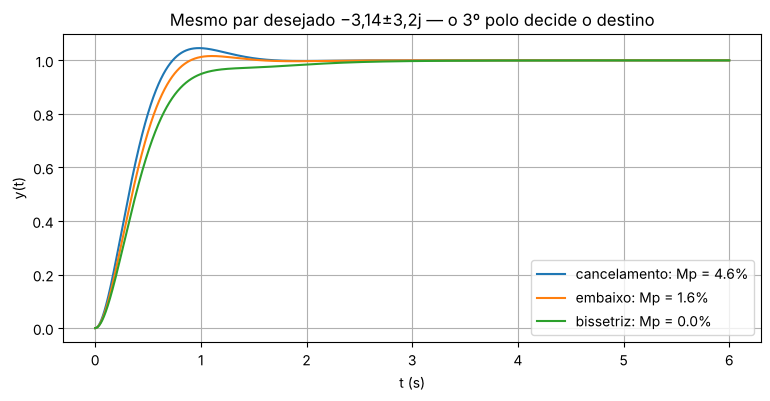

In [4]:
sd = -3.14 + 3.2j
resultados = {}
for modo, kw in [('cancelamento', dict(polo_cancela=4)), ('embaixo', {}), ('bissetriz', {})]:
    Cav, phi = projetar_avanco(G, sd, A=4, modo=modo, **kw)
    T = ct.feedback(Cav*G, 1)
    m = medir(T)
    resultados[modo] = (Cav, T, m)
    print(f'{modo:13s}: C(s) = {Cav}  → polos MF: {np.round(ct.poles(T),2)}')
    print(f'               Mp = {m["Mp"]:.1f}%, tp = {m["tp"]:.2f} s')

t = np.linspace(0, 6, 6000)
for modo, (Cav, T, m) in resultados.items():
    plt.plot(*step(T, t), label=f'{modo}: Mp = {m["Mp"]:.1f}%')
plt.xlabel('t (s)'); plt.ylabel('y(t)'); plt.legend()
plt.title('Mesmo par desejado −3,14±3,2j — o 3º polo decide o destino');

**✏️ Responda:** as três soluções colocam o par $-3{,}14 \pm 3{,}2j$ no lugar exato.
Por que o overshoot varia de 1,6 % a 4,5 %? (Olhe o 3º polo de cada malha fechada — §2.1.8.)

In [5]:
print(f'Regra dos 5×: o 3º polo precisaria estar em |p3| ≥ 5·|Re(par)| = {5*abs(sd.real):.1f}\n')
for modo, (Cav, T, m) in resultados.items():
    p3 = [p.real for p in ct.poles(T) if abs(p.imag) < 1e-6][0]
    zero_C = -ct.zeros(Cav)[0].real
    print(f'{modo:13s}: 3º polo = {p3:6.2f} ({abs(p3)/abs(sd.real):.2f}×σ) | zero do controlador em {-zero_C:6.2f} '
          f'| Mp = {m["Mp"]:4.1f}%')

Regra dos 5×: o 3º polo precisaria estar em |p3| ≥ 5·|Re(par)| = 15.7

cancelamento : 3º polo =  -4.00 (1.27×σ) | zero do controlador em  -4.00 | Mp =  4.6%
embaixo      : 3º polo =  -2.66 (0.85×σ) | zero do controlador em  -3.14 | Mp =  1.6%
bissetriz    : 3º polo =  -1.70 (0.54×σ) | zero do controlador em  -2.30 | Mp =  0.0%


**Leitura do resultado (e resposta ao ✏️ Responda).** Cada solução coloca o **mesmo par** $-3{,}14\pm3{,}2j$ em
malha fechada, mas a planta é de 2ª ordem e o avanço acrescenta um polo e um zero: a malha fechada é de **3ª
ordem**, e quem decide é o **3º polo real** (§2.1.8, regra dos 5×, que exigiria $|p_3|\geq5\times3{,}14=15{,}7$ —
nenhuma das três soluções chega perto disso):

| Solução | 3º polo | $M_p$ | Por quê |
|---|---|---|---|
| Cancelamento | $-4{,}00$ | $4{,}6\%$ | o zero do controlador está **sobre** o polo $-4$ da planta; o 3º polo fica "colado" no zero e se cancela — sobra a 2ª ordem pura ($\zeta=0{,}7\Rightarrow M_p=4{,}6\%$) |
| Zero embaixo | $-2{,}66$ | $1{,}6\%$ | o 3º polo real **não** se cancela e está a $0{,}85\times\sigma$: perto demais, passa a dominar e amortece a resposta |
| Bissetriz | $-1{,}70$ | $0{,}0\%$ | ainda mais lento: o polo real $-1{,}7$ domina por completo e o overshoot some — a saída vira praticamente de 1ª ordem lenta |

Observação sobre o enunciado do laboratório: o intervalo "1,6 % a 4,5 %" cobre só as duas primeiras soluções; a
**bissetriz** (que tem o menor ganho, $k=3{,}71$) dá $M_p=0\%$ e o `tp = 18,5 s` impresso é apenas o `argmax`
de uma curva monótona que ainda está subindo (não há pico). O ensinamento é o mesmo do Exercício 2.3.1: as três
colocam o par desejado no lugar exato, mas só a que **cancela** o polo da planta preserva o desempenho de 2ª ordem
projetado — sempre confira **todos** os polos de malha fechada.

## Parte 3 — O PD puro e o pico do sinal de controle

Projetamos um PD para o mesmo alvo: $C_{PD} = k(s+a)$ — avanço com o polo no infinito.
O problema é o **sinal de controle**: $U/R = \dfrac{C}{1+CG}$ e a derivada do degrau é um impulso.
Simulamos o PD **com filtros** de polo cada vez mais distante ($-N$) e medimos o pico de $u(t)$:

PD ideal: C = 0.571(s + 8.8)


N =    50: pico de u =       28.6  | Mp da saída = 7.3%


N =   200: pico de u =      114.2  | Mp da saída = 6.0%


N =  1000: pico de u =      571.2  | Mp da saída = 5.7%


N = 10000: pico de u =     5711.9  | Mp da saída = 5.6%


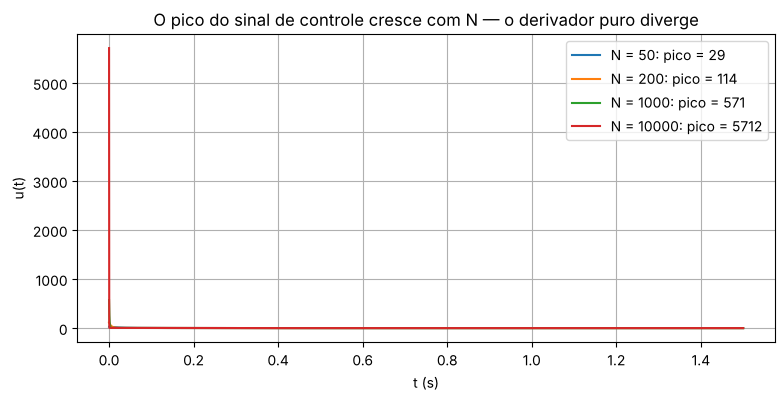

In [6]:
a_pd = 8.8
kd = np.prod([abs(sd - p) for p in ct.poles(G)])/(4*abs(sd + a_pd))
print(f'PD ideal: C = {kd:.3f}(s + {a_pd})')
t = np.linspace(0, 1.5, 15000)
for N in [50, 200, 1000, 10000]:
    Cf = kd*ct.tf([N, N*a_pd], [1, N])          # kd·(s+a)·N/(s+N)
    U = ct.feedback(Cf, G)                       # U/R = C/(1+CG)... via feedback(C,G)
    tt, u = step(U, t)
    T = ct.feedback(Cf*G, 1)
    m = medir(T)
    plt.plot(tt, u, label=f'N = {N}: pico = {u.max():.0f}')
    print(f'N = {N:5d}: pico de u = {u.max():10.1f}  | Mp da saída = {m["Mp"]:.1f}%')
plt.xlabel('t (s)'); plt.ylabel('u(t)'); plt.legend()
plt.title('O pico do sinal de controle cresce com N — o derivador puro diverge');

**✏️ Responda:**
1. Qual a relação aproximada entre o pico e $N$? (Dica: ganho de alta frequência de $U/R$.)
2. Se o seu atuador satura em ±24 V, qual $N$ máximo você aceitaria? O que isso implica no "avanço" implementado?
3. Conclua: por que "PD real = avanço de fase"?

In [7]:
# (1) pico de u(t) para um degrau unitário  ≈  C(∞) = kd·N
for N in [50, 200, 1000, 10000]:
    Cf = kd*ct.tf([N, N*a_pd], [1, N])
    tt, u = step(ct.feedback(Cf, G), t)
    print(f'N = {N:5d}: pico = {u.max():9.1f}   kd·N = {kd*N:9.1f}   razão = {u.max()/(kd*N):.3f}')

# (2) saturação em 24 V (para degrau unitário): N_max = 24/kd
N24 = 24/kd
Cf = kd*ct.tf([N24, N24*a_pd], [1, N24])
tt, u = step(ct.feedback(Cf, G), t)
m = medir(ct.feedback(Cf*G, 1))
print(f'\nN_max = 24/kd = {N24:.1f}: pico = {u.max():.1f} V | Mp = {m["Mp"]:.1f}%  (PD ideal: 5,6%)')
print('polo do filtro em', -round(N24, 1), '→ regra dos 5×: precisa |p| ≥', round(5*abs(sd.real), 1))

N =    50: pico =      28.6   kd·N =      28.6   razão = 1.000
N =   200: pico =     114.2   kd·N =     114.2   razão = 1.000
N =  1000: pico =     571.2   kd·N =     571.2   razão = 1.000


N = 10000: pico =    5711.9   kd·N =    5711.9   razão = 1.000



N_max = 24/kd = 42.0: pico = 24.0 V | Mp = 7.6%  (PD ideal: 5,6%)
polo do filtro em -42.0 → regra dos 5×: precisa |p| ≥ 15.7


**Leitura do resultado (e respostas ao ✏️ Responda).**

**1.** Como $G(s)$ é estritamente própria ($G(\infty)=0$), $U/R=\dfrac{C}{1+CG}\to C(\infty)$ para altas frequências,
e o degrau excita essas frequências no instante $t=0$. Com $C_f(s)=k_d\dfrac{N(s+a)}{s+N}$ temos $C_f(\infty)=k_dN$:
**pico $\approx k_d\cdot N$** — a tabela mostra a razão $\approx1{,}00$ em todos os $N$ ($k_d=0{,}571$: $28{,}6$,
$114$, $571$, $5\,712$). O pico cresce **linearmente** com $N$ e diverge para o derivador puro ($N\to\infty$).

**2.** Para um degrau **unitário** e atuador de $\pm24$ V: $k_dN\leq24\Rightarrow N_{max}=24/0{,}571\approx42$ (o
pico simulado dá $23{,}99$ V). Consequência: o polo do filtro fica em $-42$, e o avanço realizado é
$k_d\dfrac{42(s+8{,}8)}{s+42}$ — o overshoot da saída sobe de $5{,}6\%$ (PD ideal) para $\approx7{,}6\%$: o polo extra
não está longe o bastante para ser desprezível. Para degraus de amplitude $R$, o pico escala com $R$ (e o
$N$ aceitável cai na mesma proporção). **Projetar um PD é sempre um compromisso entre fidelidade ao PD ideal e
sinal de controle viável.**

**3.** O PD ideal $k(s+a)$ é **impróprio** (grau do numerador > grau do denominador, §2.1.2) e não existe
fisicamente; o que se implementa é $k_d\dfrac{s+a}{1+s/N}$ — um **zero em $-a$ e um polo em $-N$ muito mais
distante**, que é exatamente a definição do avanço de fase com $b\to N$ grande. Por isso "PD real = avanço de
fase": o avanço é o PD com o derivador **filtrado**.

## Parte 4 — Dois estágios e a regra dos 40°

$G(s) = \dfrac{10}{s(s+10)}$. Estágio 1: P com $M_p = 20\%$ ($k = 12{,}1$, polos $-5 \pm 9{,}8j$).
Estágio 2: avanço dobrando a velocidade ($\square_d = -10 + 19{,}6j$, contribuição $27°$):

Estágio 1 (P, k = 12,1): Mp = 20.1%, tp = 0.321 s


Estágio 2: C(s) = <TransferFunction>: sys[112]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

  48.42 s + 484.2
  ---------------
      s + 20 (avanço de 27.0°)
           Mp = 20.1%, tp = 0.160 s


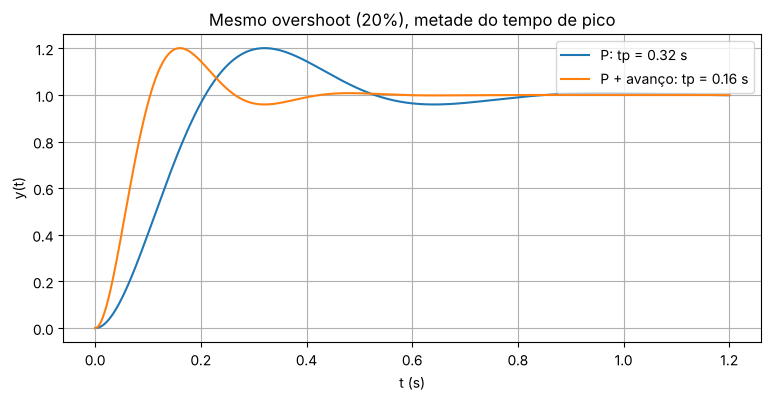

In [8]:
G = ct.tf([10], [1, 10, 0])
T1 = ct.feedback(12.1*G, 1)
m1 = medir(T1)
print(f'Estágio 1 (P, k = 12,1): Mp = {m1["Mp"]:.1f}%, tp = {m1["tp"]:.3f} s')

C2, phi = projetar_avanco(G, -10 + 19.6j, A=10, modo='cancelamento', polo_cancela=10)
T2 = ct.feedback(C2*G, 1)
m2 = medir(T2)
print(f'Estágio 2: C(s) = {C2} (avanço de {phi:.1f}°)')
print(f'           Mp = {m2["Mp"]:.1f}%, tp = {m2["tp"]:.3f} s')

t = np.linspace(0, 1.2, 12000)
plt.plot(*step(T1, t), label=f'P: tp = {m1["tp"]:.2f} s')
plt.plot(*step(T2, t), label=f'P + avanço: tp = {m2["tp"]:.2f} s')
plt.xlabel('t (s)'); plt.ylabel('y(t)'); plt.legend()
plt.title('Mesmo overshoot (20%), metade do tempo de pico');

**Leitura do resultado.** É o **Exercício 2.3.2**. O estágio 1 (P) dá $M_p\approx20\%$ e $t_p\approx0{,}32$ s. No
estágio 2 o ponto $-10+19{,}6j$ exige $\approx27°$ de avanço (abaixo dos $40°$ ✓). Com o **zero sobre o polo
$-10$** da planta, o polo do controlador contribui $90°-27°=63°$ e cai em $b\approx20$, e o ganho sai $k\approx48{,}4$:
$C(s)=48{,}4\dfrac{s+10}{s+20}$. O cancelamento elimina a ordem extra: $T(s)=\dfrac{484}{s^2+20s+484}$, 2ª ordem
**exata** com $\omega_n=22$ e $\zeta=0{,}455$ — polos $-10\pm19{,}6j$ (e o polo $-10$ cancelado). Resultado:
**mesmo overshoot ($\approx20\%$), metade do tempo de pico** ($0{,}16$ s). A regra dos $40°$ aparece quando a
contribuição necessária ultrapassa esse limite — caso do item 2 do relatório, resolvido abaixo.

---
# Respostas do relatório

## Resposta 1 — Projeto de 3ª ordem (§2.3.8): $G(s)=\dfrac{20(s+15)}{s(s+10)(s+20)}$, $\square_d=-9{,}3+21j$

**Dedução (Exercício 2.3.3).** $\angle G(\square_d)=\angle(\square_d+15)-\angle\square_d-\angle(\square_d+10)-\angle(\square_d+20)=-190{,}2°$,
logo $\angle C(\square_d)=190{,}2°-180°=+10{,}2°$ — contribuição **pequena** (o LGR já passava quase por lá); `angulo_G` normaliza para $(-180°,180°]$ e imprime $169{,}8°$, equivalente a $-190{,}2°$.
Pela **bissetriz** (zero e polo simétricos em torno da bissetriz do ângulo entre o eixo real e o vetor
origem→$\square_d$): $a=9{,}3-21\,\mathrm{tg}(5{,}1°)=7{,}4$ e $b=9{,}3+21\,\mathrm{tg}(5{,}1°)=11{,}2$, e a condição de módulo
(com $A=20$) dá $k=26{,}1$:

$$C(s)=26{,}1\,\frac{s+7{,}4}{s+11{,}2}.$$

∠G(□d) = 169.8°
contribuição necessária = 10.16°;  C(s) = <TransferFunction>: sys[123]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

  26.13 s + 194.2
  ---------------
     s + 11.17


polos de MF: [ -9.3  +21.j  -9.3  -21.j -15.388 +0.j  -7.179 +0.j]
Mp = 23.5%, tp = 150 ms
(coeficientes da teoria) Mp = 23.2%, tp = 150 ms
zeros de C·G: [-15.  +0.j  -7.43+0.j]
  polo real  -15.39  ↔ zero mais próximo  -15.00 (distância 0.39)
  polo real   -7.18  ↔ zero mais próximo   -7.43 (distância 0.25)


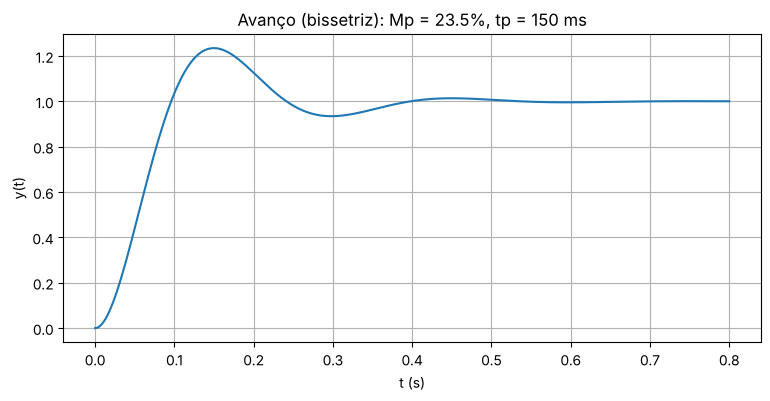

In [9]:
G = ct.tf([20, 300], [1, 30, 200, 0])          # 20(s+15)/(s(s+10)(s+20))
sd = -9.3 + 21j
print(f'∠G(□d) = {angulo_G(G, sd):.1f}°')

Cav, phi = projetar_avanco(G, sd, A=20, modo='bissetriz')
print(f'contribuição necessária = {phi:.2f}°;  C(s) = {Cav}')
T = ct.feedback(Cav*G, 1)
m = medir(T, np.linspace(0, 3, 30000))
print('polos de MF:', np.round(ct.poles(T), 3))
print(f'Mp = {m["Mp"]:.1f}%, tp = {1000*m["tp"]:.0f} ms')

# com os coeficientes arredondados da teoria (26,1 · (s+7,4)/(s+11,2))
Ct = 26.1*ct.tf([1, 7.4], [1, 11.2])
mt = medir(ct.feedback(Ct*G, 1), np.linspace(0, 3, 30000))
print(f'(coeficientes da teoria) Mp = {mt["Mp"]:.1f}%, tp = {1000*mt["tp"]:.0f} ms')

# onde caiu o 3º (e 4º) polo? Há zeros de MA por perto?
print('zeros de C·G:', np.round(ct.zeros(Cav*G), 2))
for p in ct.poles(T):
    if abs(p.imag) < 1e-6:
        zmin = min(ct.zeros(Cav*G), key=lambda z: abs(z - p))
        print(f'  polo real {p.real:7.2f}  ↔ zero mais próximo {zmin.real:7.2f} (distância {abs(zmin-p):.2f})')

plt.plot(*step(T, np.linspace(0, 0.8, 8000)))
plt.xlabel('t (s)'); plt.ylabel('y(t)'); plt.title(f'Avanço (bissetriz): Mp = {m["Mp"]:.1f}%, tp = {1000*m["tp"]:.0f} ms');

**Confirmado.** O projeto reproduz a teoria: $M_p\approx23{,}2\%$ com os coeficientes arredondados
($26{,}1$; $7{,}4$; $11{,}2$) e $23{,}5\%$ com os valores exatos de `projetar_avanco`, $t_p\approx150$ ms (teoria: 148 ms),
contra o alvo de $25\%$ e $150$ ms — a pequena diferença vem de usar fórmulas de 2ª ordem numa malha fechada de 4ª.

**Onde caíram os polos extras e eles atrapalham?** A malha fechada tem **4 polos**: o par desejado
$-9{,}3\pm21j$ e dois reais, $\approx-15{,}4$ e $\approx-7{,}2$. Cada um fica **colado em um zero** de $C\cdot G$:
$-15{,}4$ junto do zero da planta em $-15$, e $-7{,}2$ junto do zero do controlador em $-7{,}4$ — são dois
**quase-cancelamentos** (§2.1.9), cujo efeito residual é pequeno. Por isso **não atrapalham**: a dominância é
confirmada pelo desempenho medido, quase igual ao de 2ª ordem. É o contraste com o Exercício 2.3.1, em que o 3º
polo sem zero por perto destruía o desempenho.

## Resposta 2 — Regra dos 40°: $G(s)=\dfrac{1}{s(s+4)}$, $\square_d=-2+8j$ e dois avanços em cascata

**Contribuição necessária no ponto pedido.** Vetores até $\square_d=-2+8j$: do polo $0$, $\mathrm{atan2}(8,-2)=104{,}04°$;
do polo $-4$, $\mathrm{atan2}(8,2)=75{,}96°$. Logo $\angle G(\square_d)=-(104{,}04°+75{,}96°)=-180°$ e

$$\angle C(\square_d)=-\angle G(\square_d)-180°=0°.$$

**Surpresa:** o ponto $-2+8j$ **já pertence ao LGR da planta** (está na vertical $\sigma=-4/2=-2$ da §2.3.1), então
**não é preciso nenhum avanço** — e, portanto, os $40°$ **não são violados**: um P com $k=|\square_d|\cdot|\square_d+4|=68$ já
posiciona o polo ali (resultado: $\zeta=0{,}24$, $M_p\approx46\%$, $t_p=\pi/8=0{,}39$ s). Para exercitar de fato a regra
dos 40° e a cascata, usamos um alvo **fora** do LGR, com a mesma planta: $\square_d=-8+8j$ ($\zeta=0{,}71$,
$M_p\approx4{,}3\%$, $t_p\approx0{,}39$ s), que pede $\approx71{,}6°$ — **viola os $40°$**. Solução: **dois avanços iguais**,
cada um com $71{,}6°/2=35{,}8°$ (cada par pela bissetriz), com o ganho único pela condição de módulo.

(a) □d = (-2+8j): contribuição = 0.00°  → P basta (k = 68): Mp = 45.6%, tp = 0.393 s
(b) □d = (-8+8j): contribuição necessária = 71.6°  → viola os 40°? True
    projetar_avanco recusa: avanço 71.6° fora do limite de 40°!



Um avanço de 71.6°: (s+2.23)/(s+13.77), k = 101.2
  polos MF: [-8.   +8.j -8.   -8.j -1.766+0.j] | Mp = 0.0%, ts(5%) = 0.928 s
Dois avanços de 35.8°: [(s+5.42)/(s+10.58)]², k = 101.2
  polos MF: [-8.   +8.j    -8.   -8.j    -4.583+1.484j -4.583-1.484j] | Mp = 1.4%, tp = 0.483 s, ts(5%) = 0.317 s
  ∠(C·G)(□d) = 180.0° (precisa ±180°)


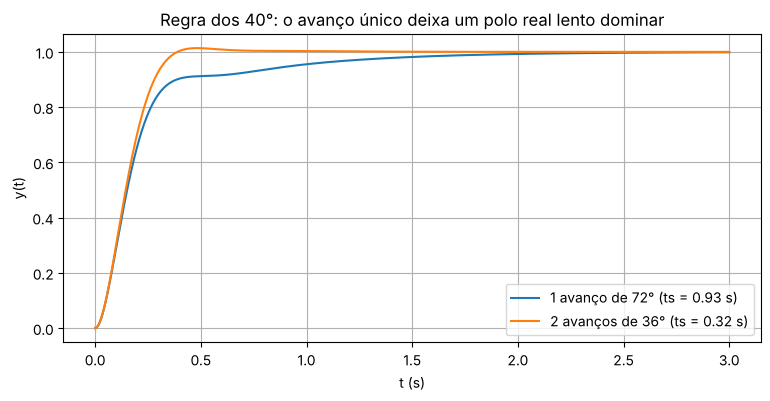

In [10]:
G = ct.tf([1], [1, 4, 0])

# (a) ponto pedido no enunciado: -2+8j
sd_a = -2 + 8j
phi_a = (-angulo_G(G, sd_a) - 180) % 360
k_a = abs(sd_a)*abs(sd_a + 4)
m_a = medir(ct.feedback(k_a*G, 1), np.linspace(0, 10, 40000))
print(f'(a) □d = {sd_a}: contribuição = {phi_a:.2f}°  → P basta (k = {k_a:.0f}): Mp = {m_a["Mp"]:.1f}%, tp = {m_a["tp"]:.3f} s')

# (b) alvo que exige > 40°
sd = -8 + 8j
phi = (-angulo_G(G, sd) - 180) % 360
print(f'(b) □d = {sd}: contribuição necessária = {phi:.1f}°  → viola os 40°? {phi > 40}')
try:
    projetar_avanco(G, sd, modo='bissetriz')
except AssertionError as e:
    print('    projetar_avanco recusa:', e)

def par_bissetriz(sd, fase):            # (s+a)/(s+b) que contribui "fase" graus em sd
    sig, wd = -sd.real, sd.imag
    t = np.tan(np.radians(fase/2))
    return sig - wd*t, sig + wd*t

def modulo_k(sd, L):                    # condição de módulo para L = C·G sem ganho
    return (np.prod([abs(sd - p) for p in ct.poles(L)]) /
            (np.prod([abs(sd - z) for z in ct.zeros(L)]) if len(ct.zeros(L)) else 1.0))

t = np.linspace(0, 3, 30000)
# um único avanço de 71,6° (ignorando a regra)
a1, b1 = par_bissetriz(sd, phi)
C1 = ct.tf([1, a1], [1, b1]); k1 = modulo_k(sd, C1*G)
T1 = ct.feedback(k1*C1*G, 1); m1 = medir(T1, t)
print(f'\nUm avanço de {phi:.1f}°: (s+{a1:.2f})/(s+{b1:.2f}), k = {k1:.1f}')
print('  polos MF:', np.round(ct.poles(T1), 3), f'| Mp = {m1["Mp"]:.1f}%, ts(5%) = {m1["ts"]:.3f} s')

# dois avanços em cascata de phi/2 cada
a2, b2 = par_bissetriz(sd, phi/2)
C2 = ct.tf([1, a2], [1, b2]); C2c = C2*C2; k2 = modulo_k(sd, C2c*G)
T2 = ct.feedback(k2*C2c*G, 1); m2 = medir(T2, t)
print(f'Dois avanços de {phi/2:.1f}°: [(s+{a2:.2f})/(s+{b2:.2f})]², k = {k2:.1f}')
print('  polos MF:', np.round(ct.poles(T2), 3), f'| Mp = {m2["Mp"]:.1f}%, tp = {m2["tp"]:.3f} s, ts(5%) = {m2["ts"]:.3f} s')
print(f'  ∠(C·G)(□d) = {angulo_G(k2*C2c*G, sd):.1f}° (precisa ±180°)')

plt.plot(*step(T1, t), label=f'1 avanço de {phi:.0f}° (ts = {m1["ts"]:.2f} s)')
plt.plot(*step(T2, t), label=f'2 avanços de {phi/2:.0f}° (ts = {m2["ts"]:.2f} s)')
plt.xlabel('t (s)'); plt.ylabel('y(t)'); plt.legend()
plt.title('Regra dos 40°: o avanço único deixa um polo real lento dominar');

**Confirmado.** (a) Com o ponto do enunciado a contribuição é **$0°$** — $-2+8j$ está sobre o LGR do P, com $k=68$ e
$M_p\approx45{,}6\%$ — então a regra dos 40° não entra em jogo; vale registrar essa observação no relatório. (b) Com o
alvo $-8+8j$ a contribuição é $71{,}6°>40°$ e `projetar_avanco` **recusa** o projeto. Forçando um avanço único
mesmo assim (zero em $2{,}2$, polo em $13{,}8$, $k\approx101$), o par $-8\pm8j$ de fato aparece, mas o terceiro polo cai
em $\approx-1{,}8$ e **domina** a resposta: o overshoot some, a curva é monótona e lenta ($t_s\approx0{,}93$ s) — o
"Fusca tentando ser Ferrari" da teoria: o polo ficou longe demais do zero e os outros polos de malha fechada pagaram
a conta. Com **dois avanços de $35{,}8°$** o par $-8\pm8j$ continua no lugar, mas os polos extras
($-4{,}6\pm1{,}5j$) ficam **mais próximos do eixo imaginário que o par desejado** — o par **não** é dominante, então
$M_p\approx1{,}4\%$ e $t_p\approx0{,}48$ s não reproduzem o alvo de 2ª ordem ($4{,}3\%$; $0{,}39$ s). Mesmo assim a cascata
é claramente melhor que o avanço único: $t_s\approx0{,}32$ s contra $0{,}93$ s, sem o polo real lento dominante.
**Moral:** a cascata contorna o limite de $40°$ por avanço, mas não é mágica — pede-se a mesma cautela de
sempre (conferir **todos** os polos) e, se o desempenho não bastar, repensar os requisitos.

## Resposta 3 — Cancelamento proibido: o polo da origem de $\dfrac{4}{s(s+4)}$

**Dedução.** Com o polo da origem **mantido** (como no avanço da §2.3.1, $C(s)=5{,}04\dfrac{s+4}{s+6{,}3}$), a malha
aberta $L=CG=\dfrac{20{,}16}{s(s+6{,}3)}$ é **tipo 1**:

$$k_p=\infty,\qquad k_v=\lim_{s\to0}sL(s)=\frac{20{,}16}{6{,}3}=3{,}2\;\Rightarrow\;e_{ss}^{\text{degrau}}=0,\quad e_{ss}^{\text{rampa}}=\frac1{k_v}=0{,}3125.$$

Se um controlador com **zero na origem** cancelasse o integrador — por exemplo $C(s)=k\dfrac{s}{s+b}$ — teríamos
$L=\dfrac{4k}{(s+b)(s+4)}$, **tipo 0**:

$$k_p=\frac{4k}{4b}=\frac kb,\qquad k_v=\lim_{s\to0}sL(s)=0\;\Rightarrow\;e_{ss}^{\text{degrau}}=\frac1{1+k/b},\quad e_{ss}^{\text{rampa}}=\frac1{k_v}=\infty.$$

Para $k=5$, $b=6$: $k_p=0{,}833$, $e_{ss}^{\text{degrau}}=0{,}545$ (antes era **zero**) e o erro à rampa **diverge**
(cresce $0{,}545$ por segundo). Cancelar o integrador troca "erro zero ao degrau e finito à rampa" por "erro
finito ao degrau e infinito à rampa".

(A) integrador mantido: kv = 3.20 → ess(rampa) = 0.3125;  medido e(50) = 0.3125
(B) integrador cancelado: L = [20.]/[ 1. 10. 24.]  → kp = 0.833, kv = 0
    ess(degrau) = 1/(1+kp) = 0.5455;  medido = 0.5455
    erro à rampa: e(10) = 5.56, e(50) = 27.38  (cresce ≈ 0.545/s → diverge)


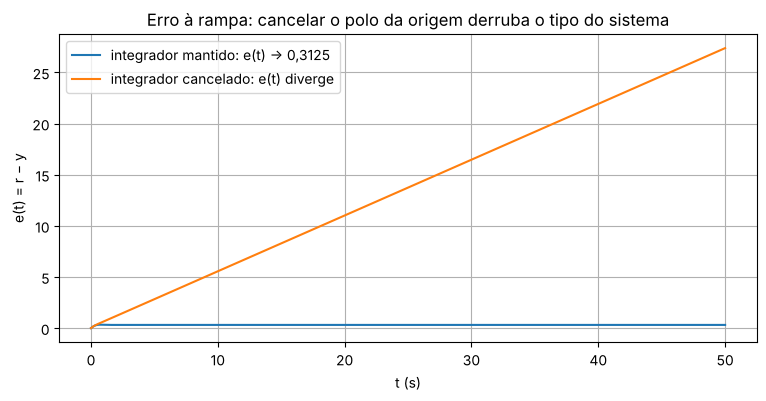

In [11]:
G = ct.tf([4], [1, 4, 0])
t = np.linspace(0, 50, 5000); r = t               # entrada rampa unitária

# (A) polo da origem mantido: avanço da §2.3.1
Ca = 5.04*ct.tf([1, 4], [1, 6.3])
La = Ca*G
kv = ct.minreal(La*ct.tf([1, 0], [1]), verbose=False).dcgain()
Ta = ct.feedback(La, 1)
_, ya = ct.forced_response(Ta, t, r); ea = r - np.asarray(ya)
print(f'(A) integrador mantido: kv = {kv:.2f} → ess(rampa) = {1/kv:.4f};  medido e(50) = {ea[-1]:.4f}')

# (B) zero na origem cancelando o polo do integrador: C = 5 s/(s+6)
Cb = 5*ct.tf([1, 0], [1, 6])
Lb = ct.minreal(Cb*G, verbose=False)
kp = Lb.dcgain()
Tb = ct.feedback(Lb, 1)
_, yb = ct.forced_response(Tb, t, r); eb = r - np.asarray(yb)
_, ydeg = ct.forced_response(Tb, t, np.ones_like(t))
print(f'(B) integrador cancelado: L = {Lb.num[0][0]}/{Lb.den[0][0]}  → kp = {kp:.3f}, kv = 0')
print(f'    ess(degrau) = 1/(1+kp) = {1/(1+kp):.4f};  medido = {1-ydeg[-1]:.4f}')
print(f'    erro à rampa: e(10) = {eb[1000]:.2f}, e(50) = {eb[-1]:.2f}  (cresce ≈ {1/(1+kp):.3f}/s → diverge)')

plt.plot(t, ea, label='integrador mantido: e(t) → 0,3125')
plt.plot(t, eb, label='integrador cancelado: e(t) diverge')
plt.xlabel('t (s)'); plt.ylabel('e(t) = r − y'); plt.legend()
plt.title('Erro à rampa: cancelar o polo da origem derruba o tipo do sistema');

**Confirmado.** Com o integrador mantido, $k_v=3{,}2$ e o erro à rampa converge para $0{,}3125$ (simulação: $e(50)=0{,}3125$).
Com o integrador cancelado, $k_v=0$: o erro ao degrau, que era nulo, passa a $0{,}545$ ($=1/(1+k_p)$, $k_p=0{,}833$), e o
erro à rampa **cresce sem limite** a $\approx0{,}545$ por segundo ($e(50)\approx27$). É por isso que, na §2.3.4, a
terceira solução-padrão cancela o polo $-10$ ou $-20$ **mas nunca o polo na origem**: o integrador é justamente o que
garante o tipo 1, e perdê-lo derruba $k_v$ a zero.